In [1]:
import ast
import pandas as pd
import matplotlib.pyplot as plt
import datasets as load_datasets

#Loading data
datasets = load_datasets.load_dataset('lukebarousse/data_jobs')
df = datasets['train'].to_pandas()

#Data cleaning
df['job_posted_date'] = pd.to_datetime(df['job_posted_date'])
df['job_skills'] = df['job_skills'].apply(lambda x: ast.literal_eval(x) if pd.notna(x) else(x))

In [ ]:
df[['job_title_short', 'job_skills']].head()

In [4]:
df_exploded = df.explode('job_skills')

In [5]:
skill_count = df_exploded.groupby(['job_title_short', 'job_skills']).size()

In [ ]:
df_skill_count = skill_count.reset_index(name='skill_count')
df_skill_count = df_skill_count.sort_values(by='skill_count', ascending=False)

df_skill_count

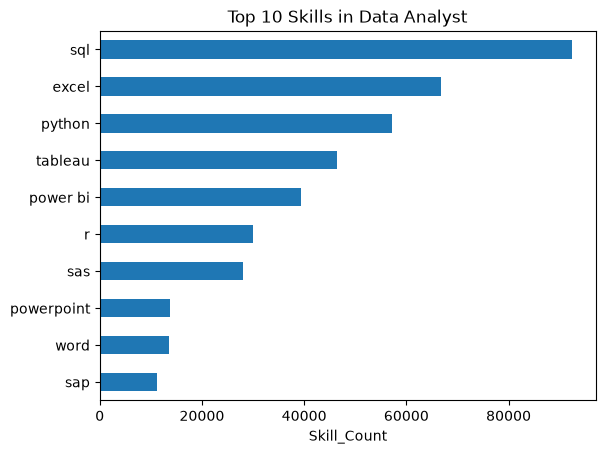

In [28]:
job_title = 'Data Analyst'
top_skills = 10

df_skills_final = df_skill_count[df_skill_count['job_title_short'] == job_title].head(top_skills)
df_skills_final.plot(kind='barh', x='job_skills', y='skill_count')
plt.gca().invert_yaxis()
plt.title(f'Top {top_skills} Skills in {job_title}')
plt.xlabel('Skill_Count')
plt.ylabel('')
plt.legend().set_visible(False)
plt.show()